# Hwang et al. 2022 — PDAC
## Step 03 — Developmental module signatures & Gate 2

Gast / pSom / Crest signatures scored with the **union control pool**. Deliverable signature UMAPs
show **raw** per-cell scores (BINDING: smoothing aids the analysis but raw is the deliverable);
geography/correlation reads use the graph-**smoothed** scores from step 02.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]; print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0], '| geometry:', adata.uns.get('geometry'))

Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present
cells: 64401 | geometry: Linear-pSom/Crest


### Module geography & pseudotime gradients (Gate 2 evidence)

In [4]:
print('global module means (raw score_genes):', {l:round(float(adata.obs[l].mean()),4) for l in ['Gast','pSom','Crest']})
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
gh = adata.obs['Gast_sm'] >= adata.obs['Gast_sm'].quantile(0.9)
print(f'Gast-high decile mean pseudotime = {tn[gh.values].mean():.2f} (root if ~0)')
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

global module means (raw score_genes): {'Gast': -0.0045, 'pSom': -0.0019, 'Crest': 0.0025}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.330
  Crest_sm vs Gast_sm: r = -0.300
  Crest_sm vs pSom_sm: r = -0.387
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.655
  pSom_sm: rho = +0.111
  Crest_sm: rho = +0.144
Gast-high decile mean pseudotime = 0.11 (root if ~0)
Crest-high decile mean pseudotime = 0.50


### Gate 2 = GO (non-branching); Gate 3 = NA
The three modules are present with **organized single-axis geography**: Gast is high at the
developmental (root) pole and decreases along pseudotime (rho≈-0.66); pSom and Crest rise toward the
terminus; Gast opposes pSom/Crest spatially (Gast<->pSom r≈-0.33). This is the **non-branching case**
(§1: Gast/pSom overlap with organized cross-repression + a terminal Crest gradient) — it **passes
Gate 2 (GO)** and has no bifurcation, so **Gate 3 = NA**. Crest does **not** enrich a Gast arm
(Crest<->Gast r≈-0.30) -> **no inversion flag**.

In [5]:
adata.uns['gate2']='GO'; adata.uns['gate3']='NA'; adata.uns['crest_arm']='no inversion (Crest opposes Gast)'
print('Gate 2:', adata.uns['gate2'], '| Gate 3:', adata.uns['gate3'])

Gate 2: GO | Gate 3: NA


### Module maps (raw scores, house linear layout) — quick view

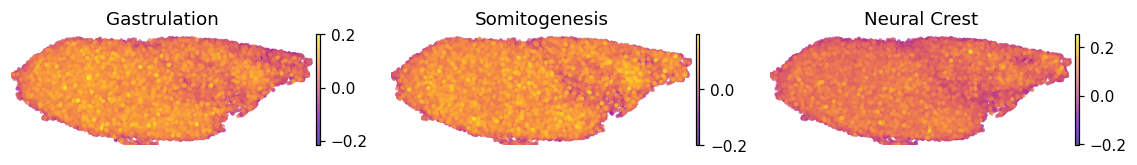

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7]); px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right', frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout(); plt.show()

### Deliverables — `{Gast,pSom,Crest}_signature.pdf` + colorbars (raw scores)

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


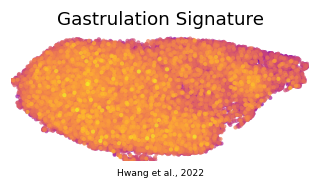

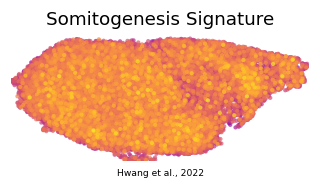

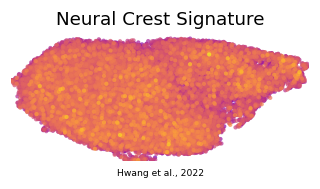

In [7]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7]); px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None, frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight'); plt.show()
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max()); ticks = np.round(np.linspace(lo,hi,5),2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight'); plt.close(fcb)
    print('saved', f'{m}_signature.pdf + colorbar')

In [8]:
adata.write(os.path.join(pth_out, 'signatures.h5ad')); print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (64401, 19457)
